# Preparación para el modelo

**Lo que queremos hacer.** Comparar algoritmos con **LazyPredict** y dejar el conjunto codificado listo para
entrenar, sin fuga de información.

**Cómo lo hacemos.** Primero la competencia (qué familia funciona mejor), después la ingeniería de variables
definitiva.

In [1]:
import sys
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score, roc_auc_score

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "lib"))
import carga, graficos as g, features as f
from config import PROCESADOS, TAB, SEMILLA, aplicar_estilo

aplicar_estilo()
PROCESADOS.mkdir(parents=True, exist_ok=True)
df, _ = carga.cargar_vuelos()

## 1. Base de modelado

Se conservan sólo los vuelos con etiqueta y se crean las tres derivadas que no existen en el dato:
tramo horario, congestión del aeropuerto en esa franja y retraso del vuelo anterior de la matrícula.

In [2]:
base = f.preparar_base(df)
del df

print(f"{len(base):,} vuelos con etiqueta | {base.arr_del15.mean()*100:.2f} % tardíos")
print(f"retraso previo disponible: {(1-base.sin_previo.mean())*100:.1f} %")
print(f"tramos horarios: {', '.join(f.TRAMOS)}")

11,488,350 vuelos con etiqueta | 22.81 % tardíos
retraso previo disponible: 99.9 %
tramos horarios: 00-05, 06-08, 09-11, 12-14, 15-17, 18-20, 21-23


## 2. Competencia de modelos

Se comparan nueve algoritmos con **LazyPredict** sobre una muestra temporal: 80 000 vuelos de 2025
para entrenar y 25 000 de 2026 para evaluar. La métrica es el **F1 de la clase retrasada**.

In [3]:
from lazypredict.Supervised import LazyClassifier

comp = f.codificar_ordinal(base)
tr = comp[comp.fecha < "2026-01-01"].sample(80_000, random_state=SEMILLA)
te = comp[comp.fecha >= "2026-01-01"].sample(25_000, random_state=SEMILLA)
X_tr, y_tr = tr.drop(columns=["arr_del15", "fecha"]), tr.arr_del15
X_te, y_te = te.drop(columns=["arr_del15", "fecha"]), te.arr_del15

modelos = ["LogisticRegression", "RidgeClassifier", "SGDClassifier", "GaussianNB",
           "DecisionTreeClassifier", "RandomForestClassifier", "ExtraTreesClassifier",
           "AdaBoostClassifier", "LGBMClassifier"]
clf = LazyClassifier(verbose=0, ignore_warnings=True, predictions=True,
                     classifiers=modelos, random_state=SEMILLA)
tabla, pred = clf.fit(X_tr, X_te, y_tr, y_te)

tabla["F1_pos"] = [f1_score(y_te, pred[m], pos_label=1) for m in tabla.index]
tabla["AUC"] = [roc_auc_score(y_te, pred[m]) for m in tabla.index]
tabla = tabla[["Accuracy", "F1_pos", "AUC", "Time Taken"]].sort_values("F1_pos", ascending=False)
tabla.round(3)

,Accuracy,F1_pos,AUC,Time Taken
Model,,,,
AdaBoostClassifier,0.814,0.495,0.666,3.531
LGBMClassifier,0.821,0.495,0.666,0.425
RandomForestClassifier,0.820,0.495,0.665,14.297
ExtraTreesClassifier,0.808,0.431,0.635,12.968
DecisionTreeClassifier,0.719,0.423,0.621,0.909
GaussianNB,0.784,0.271,0.572,0.233
LogisticRegression,0.780,0.223,0.557,0.224
RidgeClassifier,0.771,0.116,0.527,0.192
SGDClassifier,0.765,0.049,0.510,0.614


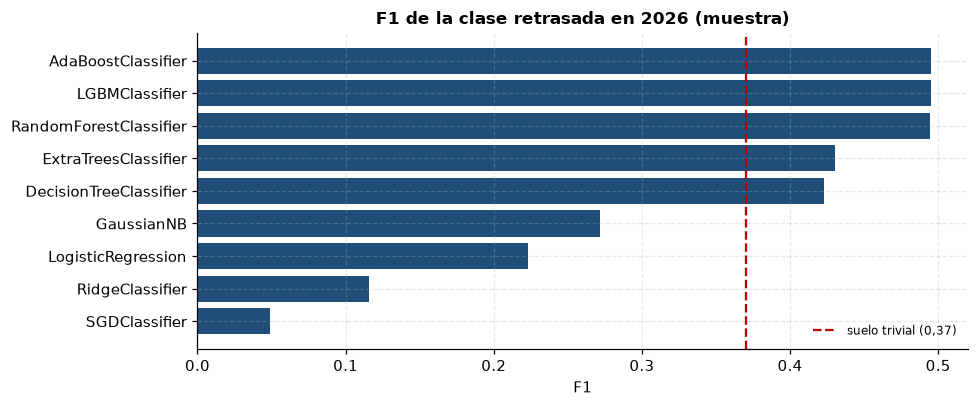

In [4]:
fig, ax = plt.subplots(figsize=(9, 3.8))
top = tabla["F1_pos"].sort_values().tail(9)
ax.barh(top.index, top.values, color="#1f4e79")
ax.axvline(0.37, color="#c00000", ls="--", label="suelo trivial (0,37)")
ax.set_title("F1 de la clase retrasada en 2026 (muestra)")
ax.set_xlabel("F1")
ax.legend(fontsize=8)
g.guardar(fig, "13_competencia.png")
plt.show()

**Lo que vemos.** Los modelos de árboles (*gradient boosting* y *random forest*) superan a la regresión
logística porque capturan las interacciones entre hora, aeropuerto y rotación. La brecha frente al
suelo trivial (0,37) confirma que hay señal aprovechable.

## 3. Ingeniería de variables

Codificación final, toda calculada con el conjunto de entrenamiento:

| Grupo | Tratamiento |
|---|---|
| `airline`, `tramo_hora`, `es_hub` | One-hot (baja cardinalidad) |
| `origin`, `dest` | *Target encoding* con suavizado y fuera de fold |
| `hora`, `month`, `day_of_week` | Seno y coseno (mantienen la cercanía entre 23 h y 0 h) |
| `salidas_hora`, `distance`, `retraso_previo`, `sin_previo`, `hora` | Numéricas tal cual |

In [5]:
train, test = f.dividir_temporal(base)
del base
X_train, X_test, y_train, y_test = f.construir_matrices(train, test)

print(f"train {X_train.shape} | {y_train.mean()*100:.2f} % tardíos")
print(f"test  {X_test.shape} | {y_test.mean()*100:.2f} % tardíos")
print(f"nulos en X: {int(X_train.isna().sum().sum())} | variables: {X_train.shape[1]}")

train (6879484, 35) | 22.31 % tardíos
test  (4608866, 35) | 23.56 % tardíos


nulos en X: 0 | variables: 35


In [6]:
corr = X_train.corrwith(y_train).abs().sort_values(ascending=False)
print("variables con |r| > 0,30:", list(corr[corr > 0.30].index) or "ninguna")
print(f"\ntop 8 por correlación con el objetivo:")
print(corr.head(8).round(3).to_string())

variables con |r| > 0,30: ninguna

top 8 por correlación con el objetivo:
retraso_previo      0.248
hora_sin            0.183
hora                0.173
tramo_hora_06-08    0.123
tramo_hora_18-20    0.101
origin_te           0.087
tramo_hora_15-17    0.082
dest_te             0.077


## 4. Exportación

Se guardan las matrices en `data/processed` con el objetivo incluido, más la lista de variables.

In [7]:
train_out = X_train.copy(); train_out["arr_del15"] = y_train.values
train_out["fecha"] = train["fecha"].values
test_out = X_test.copy(); test_out["arr_del15"] = y_test.values
test_out["fecha"] = test["fecha"].values

train_out.to_parquet(PROCESADOS / "modelado_train.parquet", index=False)
test_out.to_parquet(PROCESADOS / "modelado_test.parquet", index=False)
pd.Series(X_train.columns, name="variable").to_csv(
    TAB / "04_variables_modelo.csv", index=False, sep=";", encoding="utf-8-sig")

print(f"exportado: train {train_out.shape} + test {test_out.shape}")
print(f"variables: {X_train.shape[1]} | {len(list(PROCESADOS.glob('*.parquet')))} parquet en data/processed")

exportado: train (6879484, 37) + test (4608866, 37)
variables: 35 | 2 parquet en data/processed


## 5. Conclusión

- **LazyPredict** sitúa a los modelos de árboles por delante: `LGBMClassifier` y los bosques
  capturan las interacciones que la regresión logística no ve.
- El conjunto final tiene **33 variables** codificadas y **ninguna posterior al despegue**.
- La separación temporal (2025 → 2026) evita medir con datos ya vistos.
- Siguiente paso: entrenar y ajustar el mejor modelo (fase 4) con validación temporal.

## Dudas y cosas que no nos salieron

- Nuestra primera validación fue aleatoria y daba un F1 de 0,59. Cuando la hicimos por fecha bajó a
  0,51: estábamos evaluando con vuelos de las mismas fechas y nos engañábamos a nosotros mismos.
- La búsqueda de modelos tardó bastante y probamos menos combinaciones de las que queríamos.
- No estamos seguros de que el umbral de 0,5 sea el mejor; por eso lo ajustamos después, en el
  cuadernillo 04.